This is an experimental notebook to lay out how the forward modelling approach should work in nirspectroperf. It pre-dates the template that will be made and thus is strictly for experimentation.

In [1]:
from pathlib import Path

import numpy as np
from matplotlib import pyplot as plt

from astropy import units as u
from astropy.coordinates import SkyCoord, SpectralCoord
from astropy import visualization as aviz
aviz.quantity_support()

from jwst import datamodels

import nirspectroperf

from jax import numpy as jnp
import jaxon

from tqdm.auto import tqdm


import math

from numba import cuda

# Data Loading and Prep

In [2]:
n6791fits = list(Path('../ngc6791_cals').glob('*.fits'))

dm0 = datamodels.open(n6791fits[0])

slit = dm0.slits[49]
scoord = SkyCoord(slit.source_ra, slit.source_dec, unit='deg')

assert slit.source_name == '2609_21'

In [3]:
apogee_id = '2M19210086+3745339'
apogee_vhelio_avg = -45.42058
apogee_vunc = 0.1100559
apogee_teff = 4416.742
apogee_logg = 2.269546
apogee_m_h = 0.34755

apogee_feh = np.log10(apogee_m_h)

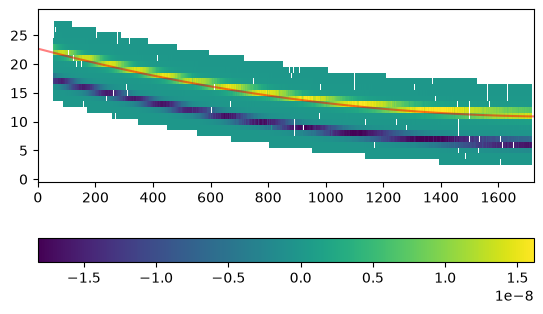

In [4]:
pos0 = SkyCoord(slit.source_ra*u.deg, slit.source_dec*u.deg)
specc = SpectralCoord(np.linspace(0.7, 1.4, 1000)*u.micron)
xtrace, ytrace = slit.meta.wcs.world_to_pixel(pos0, specc)

plt.plot(xtrace, ytrace, 'r-', alpha=.5)

sc,_ = aviz.imshow_norm(slit.data, stretch=aviz.LinearStretch(), interval=aviz.PercentileInterval(99.5), 
                                   aspect=20, origin='lower', interpolation='nearest')
plt.colorbar(sc, ax=plt.gca(), orientation='horizontal')

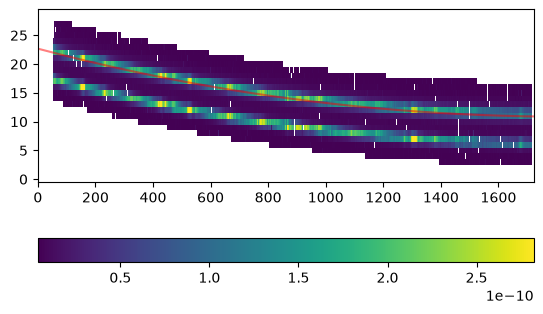

In [5]:
plt.plot(xtrace, ytrace, 'r-', alpha=.5)

sc,_ = aviz.imshow_norm(slit.err, stretch=aviz.LinearStretch(), interval=aviz.PercentileInterval(99.5), 
                                  aspect=20, origin='lower', interpolation='nearest')
plt.colorbar(sc, ax=plt.gca(), orientation='horizontal')

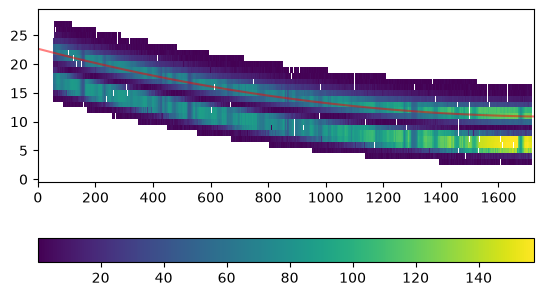

In [6]:
plt.plot(xtrace, ytrace, 'r-', alpha=.5)

sc,_ = aviz.imshow_norm(np.abs(slit.data)/slit.err, stretch=aviz.LinearStretch(), interval=aviz.PercentileInterval(99.5), 
                                                  aspect=20, origin='lower', interpolation='nearest')
plt.colorbar(sc, ax=plt.gca(), orientation='horizontal')

The model doesn't currently know what to do with negatives, so we just nan them for now

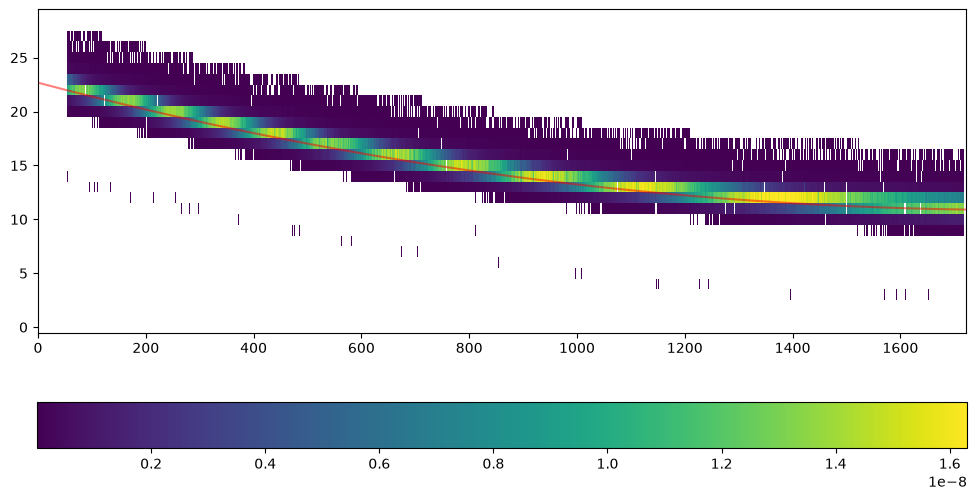

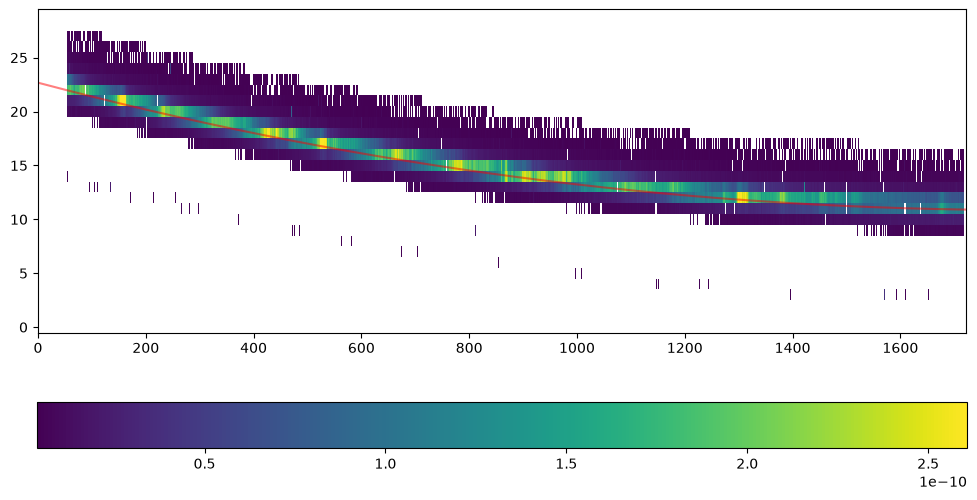

In [7]:
negmsk = slit.data < 0

naneddata = np.copy(slit.data)
naneddata[negmsk] = np.nan
nanederr = np.copy(slit.err)
nanederr[negmsk] = np.nan

fig1 = plt.figure(figsize=(12, 6))
plt.plot(xtrace, ytrace, 'r-', alpha=.5)
sc,_ = aviz.imshow_norm(naneddata, stretch=aviz.LinearStretch(), interval=aviz.PercentileInterval(99.5), 
                                                  aspect=20, origin='lower', interpolation='nearest')
plt.colorbar(sc, ax=plt.gca(), orientation='horizontal')

fig2 = plt.figure(figsize=(12, 6))
plt.plot(xtrace, ytrace, 'r-', alpha=.5)
sc,_ = aviz.imshow_norm(nanederr, stretch=aviz.LinearStretch(), interval=aviz.PercentileInterval(99.5), 
                                                  aspect=20, origin='lower', interpolation='nearest')
plt.colorbar(sc, ax=plt.gca(), orientation='horizontal')

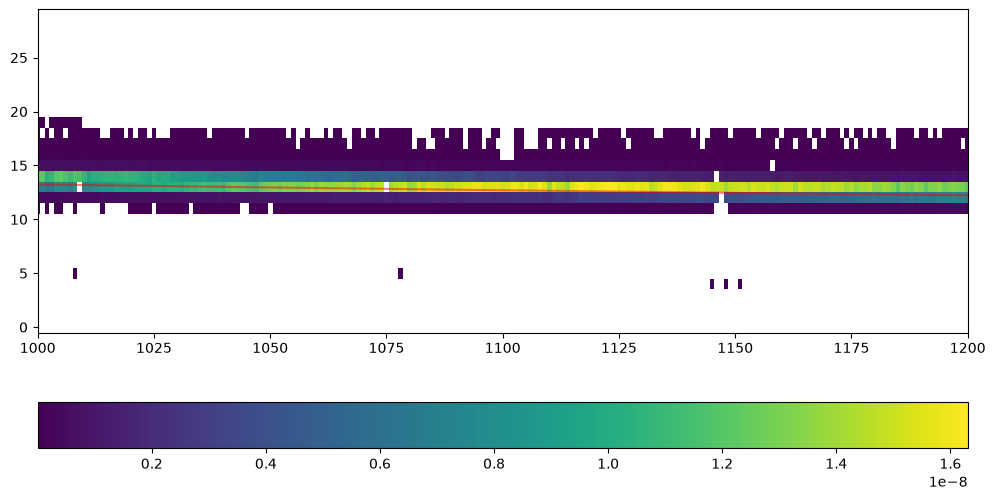

In [8]:
fig1.axes[0].set_xlim(1000, 1200)
fig1.axes[0].set_aspect('auto')
fig1

Set the model parameters to use below for testing

In [9]:
true_params = [1, 0, 0, apogee_vhelio_avg, apogee_teff, apogee_logg, apogee_feh]
true_params

[1, 0, 0, -45.42058, 4416.742, 2.269546, np.float64(-0.45898270715434314)]

Choose a set of model parameters that match one of the direct models but are fairly close to the above

In [10]:
trueish_params = [1, 0, 0, 0, 4400, 2.5, -.5]

# Direct Model

Do some sanity checks with the direct model to comapre below to the accelerated models

/var/home/erik/astro/m31_jwst_2609_vol2/.pixi/envs/gpu/lib/python3.14/site-packages/cupyx/jit/_interface.py:247: FutureWarning: cupyx.jit.rawkernel is experimental. The interface can change in the future.
  cupy._util.experimental('cupyx.jit.rawkernel')


iterating query, tdelta=3.0

MAST OPD query around UTC: 60136.5904089294
                        MJD: 60136.5904089294

OPD immediately preceding the given datetime:
	URI:	 mast:JWST/product/R2023071203-NRCA3_FP1-1.fits
	Date (MJD):	 60136.5363
	Delta time:	 -0.0542 days

OPD immediately following the given datetime:
	URI:	 mast:JWST/product/R2023071403-NRCA3_FP1-1.fits
	Date (MJD):	 60138.8979
	Delta time:	 2.3075 days
User requested choosing OPD time closest in time to 60136.5904089294, which is R2023071203-NRCA3_FP1-1.fits, delta time -0.054 days
Importing and format-converting OPD from /home/erik/data/stpsf-data/MAST_JWST_WSS_OPDs/R2023071203-NRCA3_FP1-1.fits
Backing out SI WFE and OTE field dependence at the WF sensing field point (NRCA3_FP1)
Sensing inst model using apername NRCA3_FP1
Using sensing field point SI WFE model from file wss_target_phase_fp1.fits


(<Quantity -0.0656 arcsec>, <Quantity 0.06946001 arcsec>)

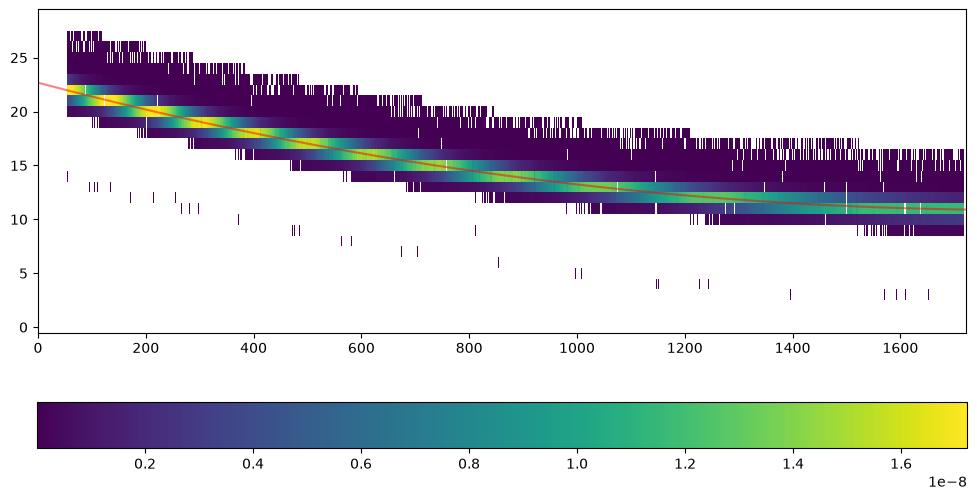

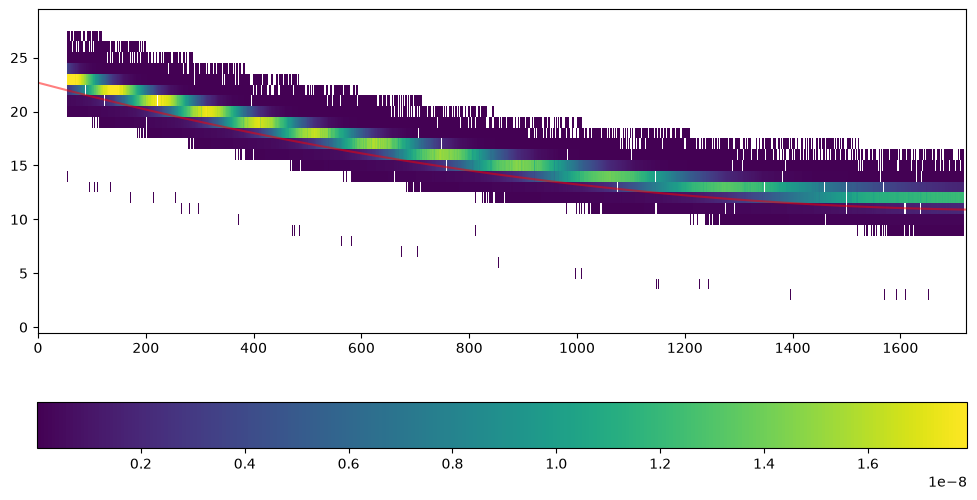

In [11]:
direct_model = nirspectroperf.NIRSpecSlitStarModel.make_from_template(dm0, slit)
direct_model.slit_data_template = naneddata  

trueish_paramst = trueish_params.copy()
trueish_paramst[0] = 1
trueish_paramst[1] = 0.
trueish_paramst[2] = 0.
trueish_paramst[-3:] = [4400, 2.5, -.5]


modarr = direct_model.make_model(trueish_paramst)

trueish_paramst[0] = np.nansum(naneddata) / np.nansum(modarr)

modarr = direct_model.make_model(trueish_paramst)

fig1 = plt.figure(figsize=(12, 6))
plt.plot(xtrace, ytrace, 'r-', alpha=.5)
sc,_ = aviz.imshow_norm(modarr, stretch=aviz.LinearStretch(), interval=aviz.PercentileInterval(99.5), 
                                                  aspect=20, origin='lower', interpolation='nearest')
plt.colorbar(sc, ax=plt.gca(), orientation='horizontal')

# compare to a y-offset version

fig2 = plt.figure(figsize=(12, 6))

trueish_paramst[2] = 0.12 # arcsec

trueish_paramst[0] = 1
modarrt = direct_model.make_model(trueish_paramst)

trueish_paramst[0] = np.nansum(naneddata) / np.nansum(modarrt)

modarrt = direct_model.make_model(trueish_paramst)

plt.plot(xtrace, ytrace, 'r-', alpha=.5)
sc,_ = aviz.imshow_norm(modarrt, stretch=aviz.LinearStretch(), interval=aviz.PercentileInterval(99.5), 
                                                  aspect=20, origin='lower', interpolation='nearest')
plt.colorbar(sc, ax=plt.gca(), orientation='horizontal')

direct_model.x_slit0, direct_model.y_slit0

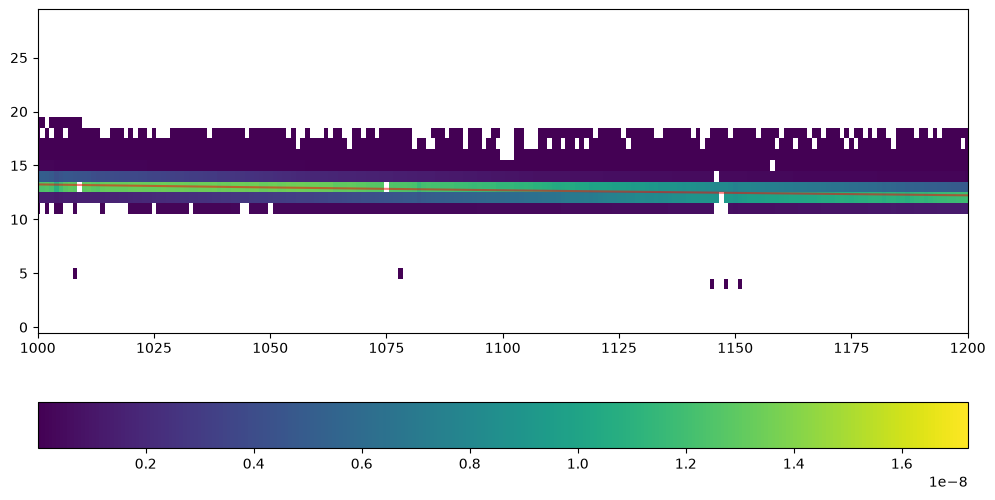

In [12]:
fig1.axes[0].set_xlim(1000, 1200)
fig1.axes[0].set_aspect('auto')
fig1

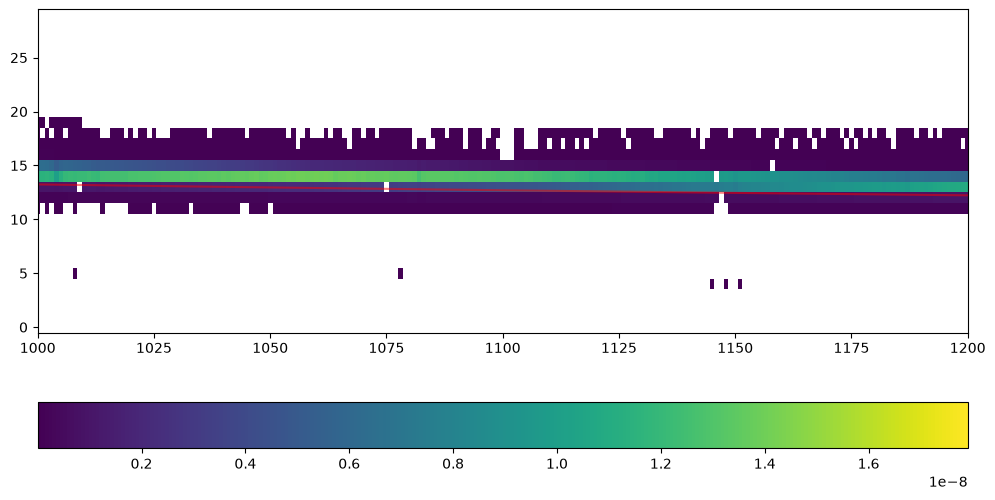

In [13]:
fig2.axes[0].set_xlim(1000, 1200)
fig2.axes[0].set_aspect('auto')
fig2

Take a look at the PSFs used for the above just to make sure it makes sense

In [14]:
trueish_paramst

[np.float32(1.1887303e-37), 0.0, 0.12, 0, 4400, 2.5, -0.5]

(np.float64(-0.06560000181198121), np.float64(0.18946001052856445))

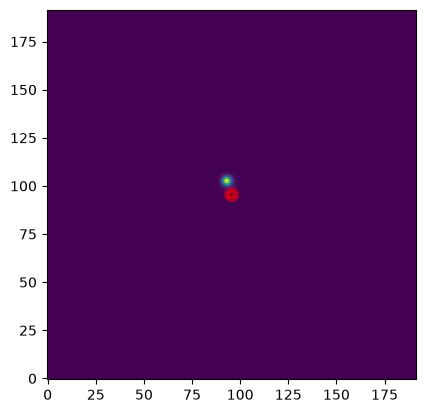

In [15]:
xo = direct_model.x_slit0.to_value(u.arcsec) + trueish_paramst[1]
yo = direct_model.y_slit0.to_value(u.arcsec) + trueish_paramst[2]

plt.imshow(direct_model.psf_model.evaluate_psf(xo, yo, 1.17*u.micron)[-1].T, origin='lower')
plt.contour(direct_model.psf_model.evaluate_psf(0, 0, 1.17*u.micron)[-1].T, colors='r', alpha=.5, lw=1)

xo,yo

-23.246213063086774 24.503786936913226 -25.691005737762733 22.058994262237267 0.6287869369132264 -1.816005737762734
-23.875 23.875 -23.875 23.875 0.0 0.0


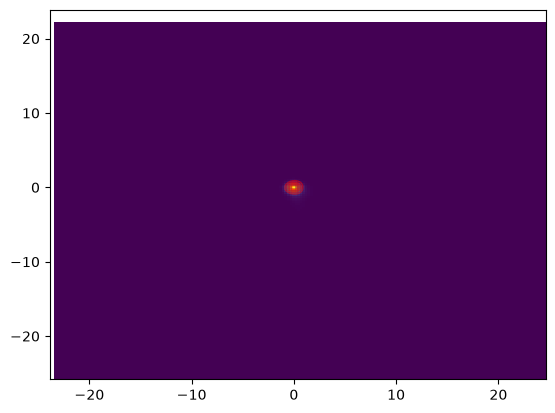

In [16]:
x,y,f = direct_model.psf_model.evaluate_psf(xo, yo, 1.17*u.micron)
print(x.min(), x.max(), y.min(), y.max(), x.mean(), y.mean())
plt.pcolor(x, y, f)

x,y,f = direct_model.psf_model.evaluate_psf(0, 0, 1.17*u.micron)
print(x.min(), x.max(), y.min(), y.max(), x.mean(), y.mean())
plt.contour(x, y, f, colors='r', alpha=.5, lw=1)

-23.246213063086774 24.503786936913226 -25.691005737762733 22.058994262237267 0.6287869369132264 -1.816005737762734
-23.246213063086774 24.503786936913226 -24.54078576298514 23.20921423701486 0.6287869369132264 -0.6657857629851396
-23.875 23.875 -23.875 23.875 0.0 0.0


(-2.5, 2.5)

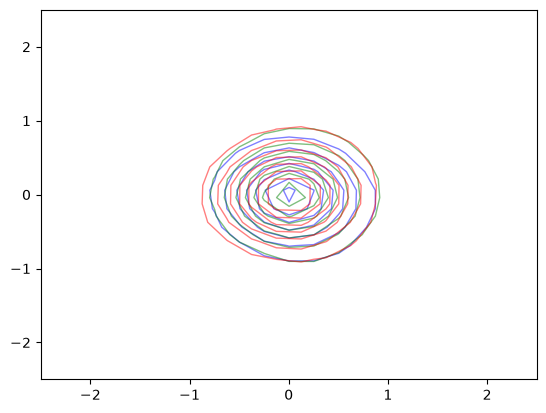

In [17]:
x,y,f = direct_model.psf_model.evaluate_psf(xo, yo, 1.17*u.micron)
print(x.min(), x.max(), y.min(), y.max(), x.mean(), y.mean())
plt.contour(x, y, f, colors='b', alpha=.5, lw=1)

x,y,f = direct_model.psf_model.evaluate_psf(direct_model.x_slit0.to_value(u.arcsec) , direct_model.y_slit0.to_value(u.arcsec) , 1.17*u.micron)
print(x.min(), x.max(), y.min(), y.max(), x.mean(), y.mean())
plt.contour(x, y, f, colors='g', alpha=.5, lw=1)

x,y,f = direct_model.psf_model.evaluate_psf(0, 0, 1.17*u.micron)
print(x.min(), x.max(), y.min(), y.max(), x.mean(), y.mean())
plt.contour(x, y, f, colors='r', alpha=.5, lw=1)

plt.xlim(-2.5, 2.5)
plt.ylim(-2.5, 2.5)

(np.float64(-2.515147747652903),
 np.float64(7.264022951050931),
 (np.float64(-0.656000018119812), np.float64(0.5628696109937584)))

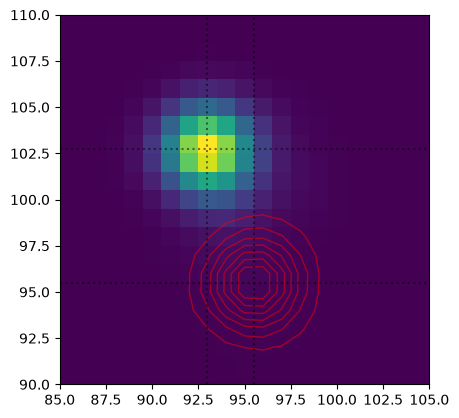

In [18]:
plt.imshow(direct_model.psf_model.evaluate_psf(xo, yo, 1.17*u.micron)[-1].T)
plt.contour(direct_model.psf_model.evaluate_psf(0, 0, 1.17*u.micron)[-1].T, colors='r', alpha=.5, lw=1)
plt.axvline(95.5, c='k', ls=':', alpha=.5)
plt.axhline(95.5, c='k', ls=':', alpha=.5)

pxoffx = (direct_model.psf_model.detector_pixelscale*xo*u.arcsec).to_value(u.pixel)*direct_model.psf_model.oversampling
pxoffy = (direct_model.psf_model.detector_pixelscale*yo*u.arcsec).to_value(u.pixel)*direct_model.psf_model.oversampling
                                                                               
plt.axvline(95.5 + pxoffx, c='k', ls=':', alpha=.5)
plt.axhline(95.5 + pxoffy, c='k', ls=':', alpha=.5)
plt.xlim(85, 105)
plt.ylim(90, 110)

pxoffx, pxoffy, direct_model.slit_offsets_frac(xo, yo)

What's up with the banding in the model vs the data?  Something seems off there.  Lets build some code based on build2d.py to investigate this.

Make a weird composite plot by marking the PSF by the number of times its accessed

In [34]:
from numba import float32

@cuda.jit
def scatter_flux_kernel_which(xspec, yspec, fluxspec,
                        psf_x, psf_y, psf_flux, 
                        startidx, nspec, 
                        outslitall,
                        oversampling, 
                        xtest, ytest, specwhichpsf):
    """
    xtest and ytest should be integers in outslitall, 
    specwhichpsf should be [nspec, xpsfsh, ypsfsh] shape
    """
    
    pixel_slope = float32(-oversampling)
    pixel_intercept = float32((1+oversampling)/2)

    x = xtest
    y = ytest
    tidx = cuda.threadIdx.x

    if math.isnan(outslitall[y, x, tidx]):
        return

    if tidx >= nspec[y, x]:
        return
    
    specidx = tidx + startidx[y, x]
    
    xsi = xspec[specidx]
    ysi = yspec[specidx]
    fsi = fluxspec[specidx]

    flux_contrib = float32(0)
    xo = float32(xsi) - float32(x)
    yo = float32(ysi) - float32(y)

    # # here we compute the lowest and highest pixel that can be influenced by the PSF.
    # # we also clamp the pixel range to be within the PSF array bounds just in case
    # npsfx = psf_x.shape[0]
    # xlower = int(math.floor((x - xsi - 1/2)*oversampling - 1) + npsfx/2)
    # xlower = max(0, xlower)
    # xupper = int(math.ceil((x - xsi + 1/2)*oversampling + 2) + npsfx/2)
    # xupper = min(npsfx, xupper)
    # xrng = xupper - xlower

    # npsfy = psf_y.shape[1]
    # ylower = int(math.floor((y - ysi - 1/2)*oversampling - 1) + npsfy/2)
    # ylower = max(0, ylower)
    # yupper = int(math.ceil((y - ysi + 1/2)*oversampling + 2) + npsfy/2)
    # yupper = min(npsfy, yupper)
    # yrng = yupper - ylower

    halfw = float32(0.5) + float32(0.5) / float32(oversampling)
    
    npsfx = psf_x.shape[0]
    x0 = psf_x[0, 0]
    xlower = int(math.floor((x - xsi - halfw - x0)*oversampling))
    xlower = max(0, xlower)
    xupper = int(math.ceil((x - xsi + halfw - x0)*oversampling)) + 1
    xupper = min(npsfx, xupper)
    xrng = xupper - xlower

    npsfy = psf_y.shape[1]
    y0 = psf_y[0, 0]
    ylower = int(math.floor((y - ysi - halfw - y0)*oversampling))
    ylower = max(0, ylower)
    yupper = int(math.ceil((y - ysi + halfw - y0)*oversampling)) + 1
    yupper = min(npsfy, yupper)
    yrng = yupper - ylower

    for iraw in range(xrng):
        for jraw in range(yrng):
            j = ylower + jraw
            i = xlower + (iraw + tidx) % xrng

            
            xpi = xo + psf_x[i, j]
            ypi = yo + psf_y[i, j]

            ox = pixel_slope * abs(xpi) + pixel_intercept
            oy = pixel_slope * abs(ypi) + pixel_intercept

            if ox <= 0 or oy <= 0:
                continue

            ox = max(float32(0), min(float32(1), ox))
            oy = max(float32(0), min(float32(1), oy))


            flux_contrib += ox*oy*fsi*psf_flux[i, j]
            specwhichpsf[i, j, specidx] = True
    #outslitall[y, x, tidx] = flux_contrib


@cuda.jit
def compute_influence_kernel(xspec, yspec, startidx, nspec, maxpsf, noncontig):
    x = cuda.blockIdx.x
    y = cuda.threadIdx.x
    maxpsfc = float32(maxpsf)

    startidxi = -1
    lastidxi = -1
    count = 0
    for i, (xs, ys) in enumerate(zip(xspec, yspec)):
        if abs(float32(x) - xs) <= maxpsfc:
            if abs(float32(y) - ys) <= maxpsfc:
                count += 1
                if startidxi == -1:
                    startidxi = i
                lastidxi = i

    startidx[y, x] = startidxi
    nspec[y, x] = count

    # scatter_flux_kernel assumes the influencing spectrum points are contiguous
    # (startidx .. startidx+nspec-1).  Flag any pixel where that's not true.
    # This could end up conflicting across threads, but  because writes only happen
    # to set it to 1, there isn't a conflict
    if count > 0 and lastidxi - startidxi + 1 != count:
        noncontig[0] = 1


def compute_influence(xspec, yspec, maxpsf, slittemplate, check_contiguous=True):
    """
    Computes where the spectrum influences the slit image, assuming a maximum
    PSF size of maxpsf.

    Returns two arrays, `startidx` and `nspec`, which are the starting index of the
    spectrum that influences each pixel, and the number of spectrum points
    that influence each pixel, respectively. Both are device arrays.

    If ``check_contiguous`` is True, raises a ValueError if the spectrum points
    influencing any pixel are not a contiguous run of indices (which
    `scatter_flux_kernel` assumes).  This requires a small device-to-host copy
    and synchronization, so it can be turned off for performance if needed.
    """
    kernelspec_influence = (slittemplate.shape[1], slittemplate.shape[0])

    xspecc = to_cuda_array_if_needed(xspec)
    yspecc = to_cuda_array_if_needed(yspec)

    startidxc = cuda.device_array(slittemplate.shape, dtype=np.int32)
    nspecc = cuda.device_array(slittemplate.shape, dtype=np.int32)
    noncontigc = cuda.to_device(np.zeros(1, dtype=np.int32))

    compute_influence_kernel[kernelspec_influence](xspecc, yspecc, startidxc, nspecc, maxpsf, noncontigc)

    if check_contiguous and noncontigc.copy_to_host()[0]:
        raise ValueError("The spectrum points influencing at least one pixel are "
                         "not contiguous in index, which scatter_flux assumes. "
                         "This probably means the trace isn't monotonic")

    return startidxc, nspecc

def to_cuda_array_if_needed(arr, dtype=np.float32):
    if cuda.is_cuda_array(arr):
        return cuda.as_cuda_array(arr)
    else:
        return cuda.to_device(arr.astype(dtype))


def scatter_flux_which(xtest, ytest,
                xspec, yspec, spectrum_fnudnu, 
                 psf_x, psf_y, psf_flux, 
                 oversampling, 
                 slittemplate, 
                 ret_host_array=False,
                 outslitall=None):
    """
    This function takes host-side arrays, and converts them into a form the GPU can use.

    ``check_contiguous`` is passed to `compute_influence`; set it to False to
    skip the (small) cost of verifying the contiguity assumption.
    """
    import cupy as cp
    xspecc = to_cuda_array_if_needed(xspec)
    yspecc = to_cuda_array_if_needed(yspec)
    fluxspecc = to_cuda_array_if_needed(spectrum_fnudnu)

    psf_xc = to_cuda_array_if_needed(psf_x)
    psf_yc = to_cuda_array_if_needed(psf_y)
    psf_fluxc = to_cuda_array_if_needed(psf_flux)

    # A spectrum point influences a pixel if any PSF subpixel overlaps it.  That
    # can happen out to the largest offset in the PSF on either side, plus half
    # a detector pixel (the pixel's own half-width) plus half a subpixel (the
    # subpixel's half-width).
    maxpsf = max(float(np.max(np.abs(psf_x))), float(np.max(np.abs(psf_y)))) + 0.5 + 0.5/oversampling
    startidxc, nspecc = compute_influence(xspecc, yspecc, float(maxpsf), slittemplate,
                                          check_contiguous=True)

    longest_stretch = int(cp.array(nspecc, copy=False).max())
    longest_stretch32 = math.ceil(longest_stretch / 32) * 32   
    assert longest_stretch32 <= 1024, f'Only 1024 threads per block, but longest stretch is {longest_stretch}'
    kernelspec = (slittemplate.shape[::-1], longest_stretch32)

    slitarr = np.zeros_like(slittemplate)
    slitarr[np.isnan(slittemplate)] = np.nan
    if outslitall is None:
        outslitall = cuda.to_device(np.repeat(np.expand_dims(slitarr, axis=-1), kernelspec[-1], axis=-1).astype(np.float32))

    outwhich = cuda.to_device(np.zeros([psf_flux.shape[0], psf_flux.shape[1], spectrum_fnudnu.shape[0]], dtype=bool))


    scatter_flux_kernel_which[kernelspec](xspecc, yspecc, fluxspecc, 
                            psf_xc, psf_yc, psf_fluxc,
                            startidxc, nspecc, 
                            outslitall, oversampling,
                            xtest, ytest, outwhich)
    if ret_host_array:
        return outwhich.copy_to_host()
    else:
        return outwhich

def make_model_which(self, model_params, xt, yt):
    F0, x_slit_offset, y_slit_offset, v, teff, logg, feh = model_params

    spec = self.spec_model.make_spectrum(teff, logg, feh)
    fnudnu = spec.flux.value*self.spec_model.dnu_hz

    raoff = decoff = 0 # might change in the future as a separate parameter?
    ra = self._ra0_deg + raoff*self._ARCSEC_TO_DEG
    dec = self._dec0_deg + decoff*self._ARCSEC_TO_DEG
    wave = self.spec_model.wave_microns*(1 + v/self._CKMS)

    xspec, yspec = self.w2p.evaluate_wcs_values(ra, dec, wave)
    xslit = self._x_slit0_asec + x_slit_offset
    yslit = self._y_slit0_asec + y_slit_offset

    psf_x, psf_y, psf_flux = self.psf_model.evaluate_psf(xslit, yslit, spec.spectral_axis.mean())

    pxperasec = self.psf_model.detector_pixelscale.to_value(u.pixel/u.arcsec)
    psf_x = psf_x + pxperasec * x_slit_offset
    psf_y = psf_y + pxperasec * y_slit_offset

    return scatter_flux_which(xt, yt, xspec, yspec, F0*fnudnu, 
                            psf_x, psf_y, psf_flux, 
                            self.psf_model.oversampling, 
                            self.slit_data_template, 
                            ret_host_array=True), psf_flux

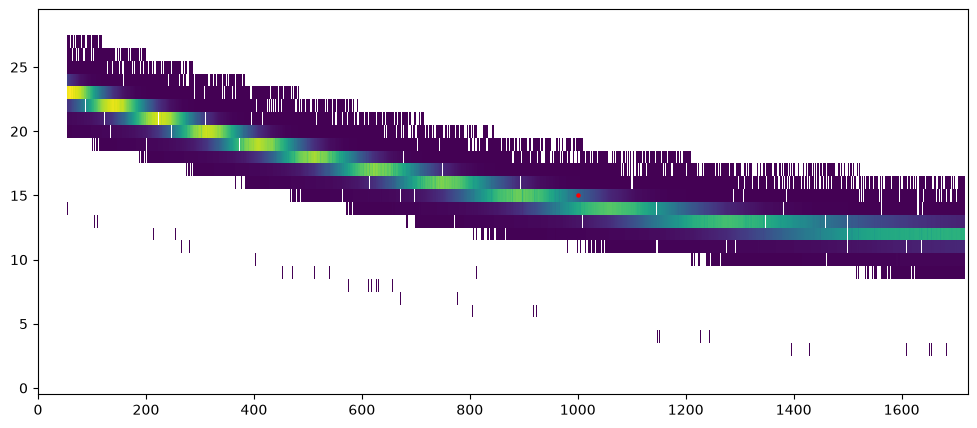

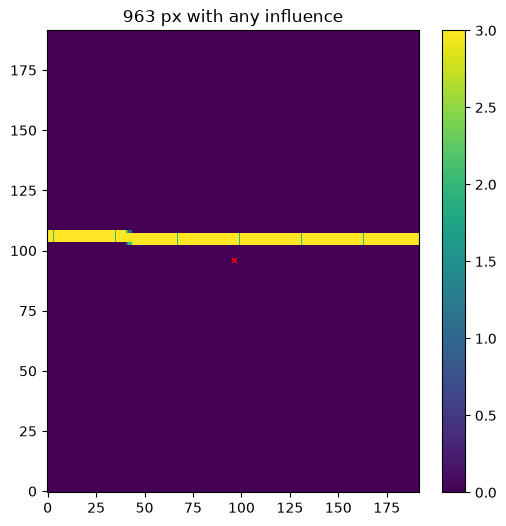

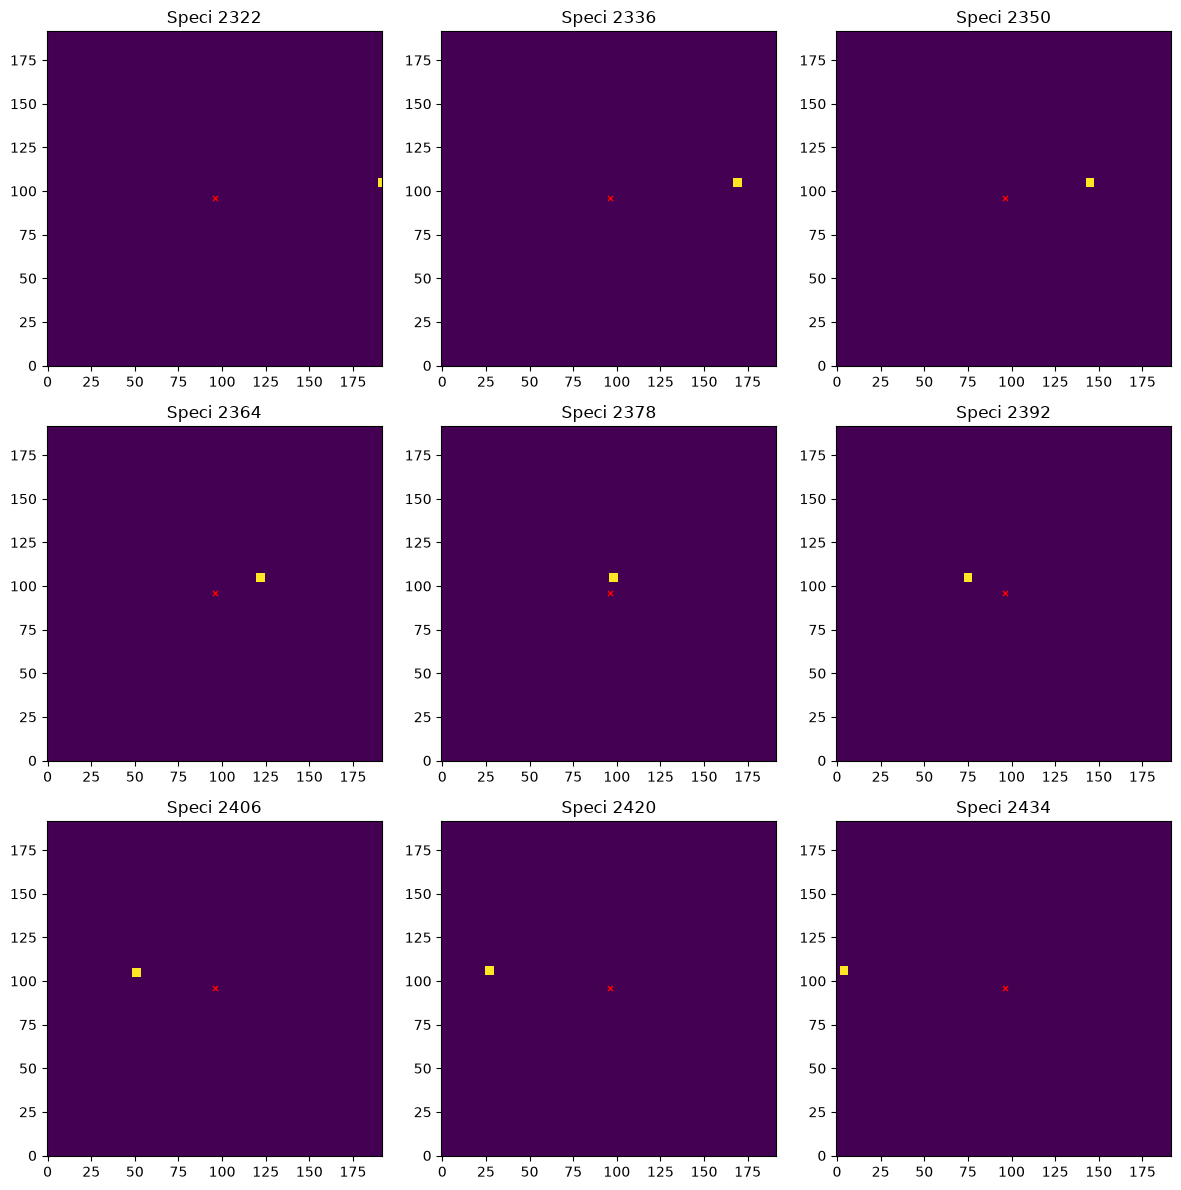

In [35]:
def show_influences(xdet, ydet, ax1=None, ax2=None, show3=True, params=trueish_paramst, model=direct_model, psfweight2=False):
    figs = []
    if ax1 is not False:
        if ax1 is None:
            figs.append(plt.figure(figsize=(12, 5)))
            ax1 = plt.gca()
        ax1.imshow(model.make_model(params), 
                aspect='auto', interpolation='nearest', origin='lower')
        ax1.scatter(xdet, ydet, color='red', s=5)

    whicharr, psf_flux = make_model_which(model, params, xdet, ydet)
    psfxs, psfys, specinds = np.where(whicharr)

    if ax2 is not False:
        if ax2 is None:
            figs.append(plt.figure(figsize=(6, 6)))
            ax2 = plt.gca()

        whichim = np.zeros((model.psf_model.last_header['NAXIS1'], model.psf_model.last_header['NAXIS2']))
        for px, py in zip(psfxs, psfys):
            whichim[px, py] += 1

        if psfweight2:
            toshow = whichim*psf_flux
        else:
            toshow = whichim
        sc = ax2.imshow(toshow.T, interpolation='nearest', origin='lower', aspect='auto')
        ax2.scatter([whichim.shape[0]//2], [whichim.shape[1]//2], color='r', s=13, marker='x', lw=1)
        plt.colorbar(sc, ax=ax2)
        ax2.set_title(f'{np.sum(whichim>0)} px with any influence')

    if show3:
        ntoshowish = 9

        fig, axs = plt.subplots(3, 3, figsize=(12, 12))

        usins = np.sort(np.unique(specinds))
        for speci, ax in zip(usins[::len(usins)//(ntoshowish-1)], axs.ravel()):
            msk = specinds == speci
            psfxs_msk = psfxs[msk]
            psfys_msk = psfys[msk]

            whichim = np.zeros((model.psf_model.last_header['NAXIS1'], model.psf_model.last_header['NAXIS2']))
            whichim[psfxs_msk, psfys_msk] = 1

            ax.imshow(whichim.T, interpolation='nearest', origin='lower')
            ax.scatter([whichim.shape[0]//2], [whichim.shape[1]//2], color='r', s=13, marker='x', lw=1)
            ax.set_title(f"Speci {speci}")

        fig.tight_layout()
        figs.append(fig)

    return figs, psf_flux

show_influences(1000,15);

In [ ]:
show_influences(1000,16);

Show a set next to each other for easier visual comparison

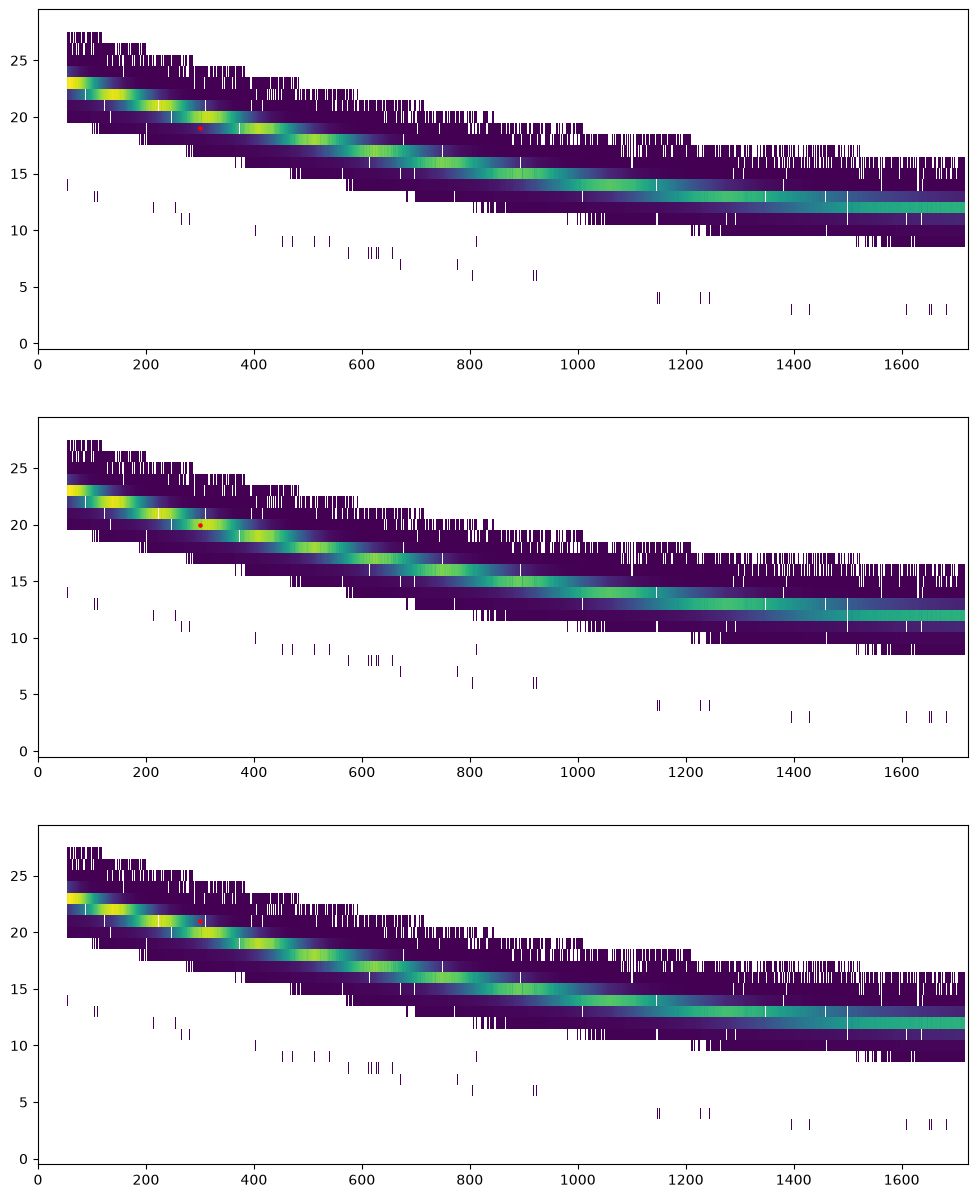

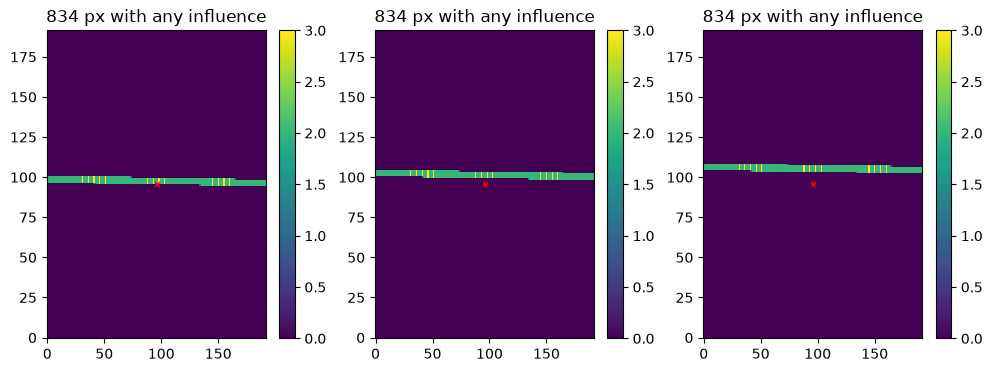

In [ ]:
fig1, axs1 = plt.subplots(3, 1, figsize=(12, 15))
fig2, axs2 = plt.subplots(1, 3, figsize=(12, 4))

show_influences(300, 19, axs1.ravel()[0], axs2.ravel()[0], False)
show_influences(300, 20, axs1.ravel()[1], axs2.ravel()[1], False)
show_influences(300, 21, axs1.ravel()[2], axs2.ravel()[2], False);


Check along a band boundary (and include a PSF comparison image)

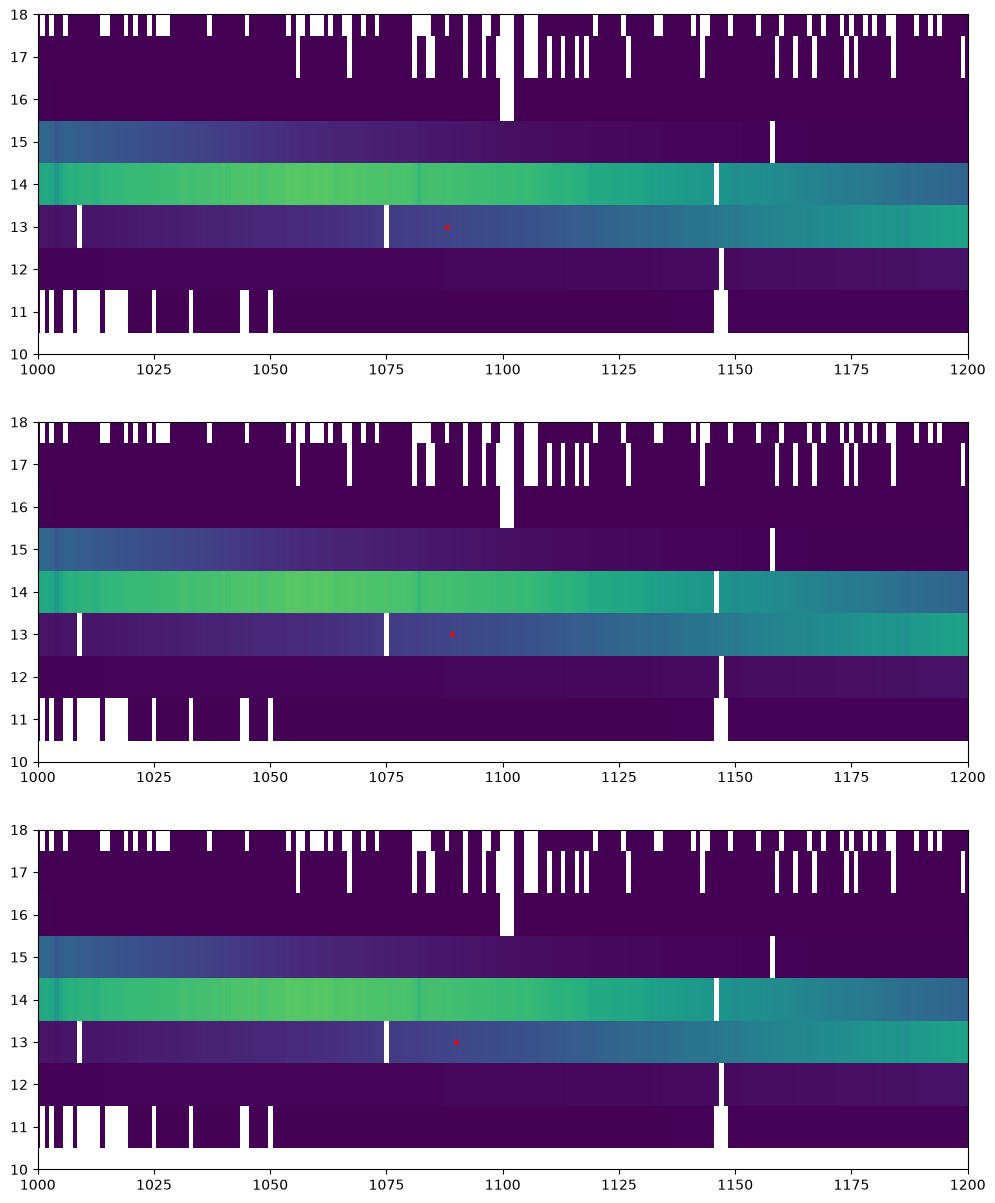

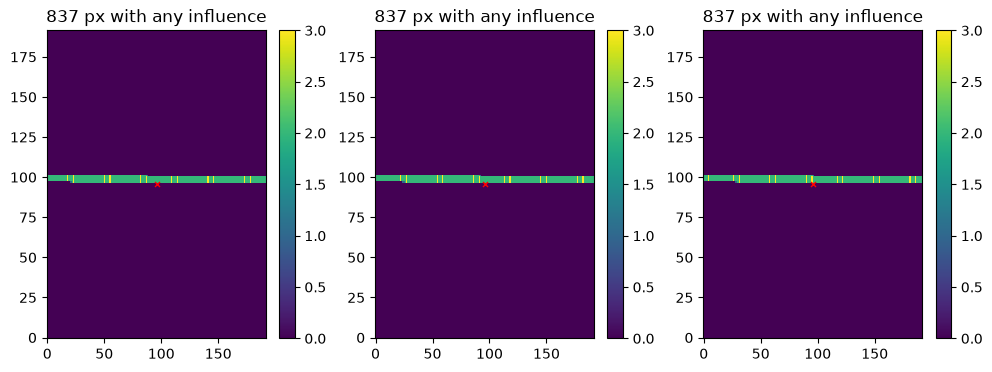

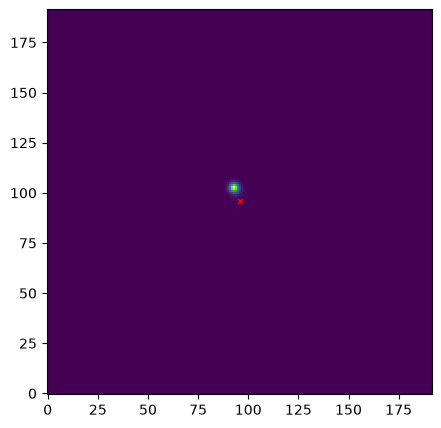

In [ ]:
fig1, axs1 = plt.subplots(3, 1, figsize=(12, 15))
fig2, axs2 = plt.subplots(1, 3, figsize=(12, 4))

show_influences(1088, 13, axs1.ravel()[0], axs2.ravel()[0], False)
show_influences(1089, 13, axs1.ravel()[1], axs2.ravel()[1], False)
show_influences(1090, 13, axs1.ravel()[2], axs2.ravel()[2], False)
for ax in axs1.ravel():
    ax.set_ylim(10, 18)
    ax.set_xlim(1000, 1200)

plt.figure(figsize=(5, 5))
xo = direct_model.x_slit0.to_value(u.arcsec) + trueish_paramst[1]
yo = direct_model.y_slit0.to_value(u.arcsec) + trueish_paramst[2]
psfeval = direct_model.psf_model.evaluate_psf(xo, yo, 1.17*u.micron)
plt.imshow(psfeval[-1].T, origin='lower', interpolation='nearest')
plt.scatter([psfeval[-1].shape[0]//2], [psfeval[-1].shape[1]//2], color='r', s=13, marker='x', lw=1)

And now what if we weight the PSF by its influence?

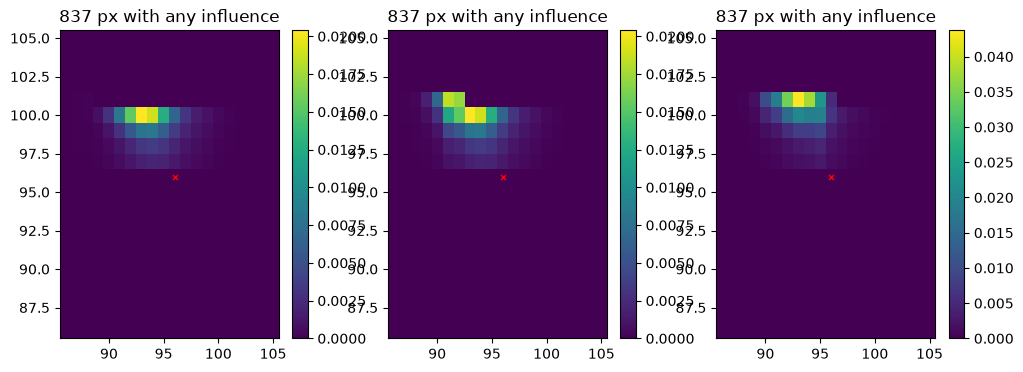

In [ ]:
fig2, axs2 = plt.subplots(1, 3, figsize=(12, 4))

show_influences(1088, 13, False, axs2.ravel()[0], False, psfweight2=True)
show_influences(1089, 13, False, axs2.ravel()[1], False, psfweight2=True)
show_influences(1090, 13, False, axs2.ravel()[2], False, psfweight2=True);

for ax in axs2.ravel():
    ax.set_xlim(85.5, 105.5)
    ax.set_ylim(85.5, 105.5)

Aha!  So the banding is due to "holes"/edges in the influence part of the PSF. Can we localize this to a specific spectral index?

In [ ]:
whicharr, psf_flux = make_model_which(direct_model, trueish_paramst, 1089, 13)
psfxs, psfys, specinds = np.where(whicharr)
uspec = np.sort(np.unique(specinds))
uspec

array([2534, 2535, 2536, 2537, 2538, 2539, 2540, 2541, 2542, 2543, 2544,
       2545, 2546, 2547, 2548, 2549, 2550, 2551, 2552, 2553, 2554, 2555,
       2556, 2557, 2558, 2559, 2560, 2561, 2562, 2563, 2564, 2565, 2566,
       2567, 2568, 2569, 2570, 2571, 2572, 2573, 2574, 2575, 2576, 2577,
       2578, 2579, 2580, 2581, 2582, 2583, 2584, 2585, 2586, 2587, 2588,
       2589, 2590, 2591, 2592, 2593, 2594, 2595, 2596, 2597, 2598, 2599,
       2600, 2601, 2602, 2603, 2604, 2605, 2606, 2607, 2608, 2609, 2610,
       2611, 2612, 2613, 2614, 2615, 2616, 2617, 2618, 2619, 2620, 2621,
       2622, 2623, 2624, 2625, 2626, 2627, 2628, 2629, 2630, 2631, 2632,
       2633, 2634, 2635, 2636, 2637, 2638, 2639, 2640, 2641, 2642, 2643,
       2644, 2645, 2646, 2647, 2648, 2649])

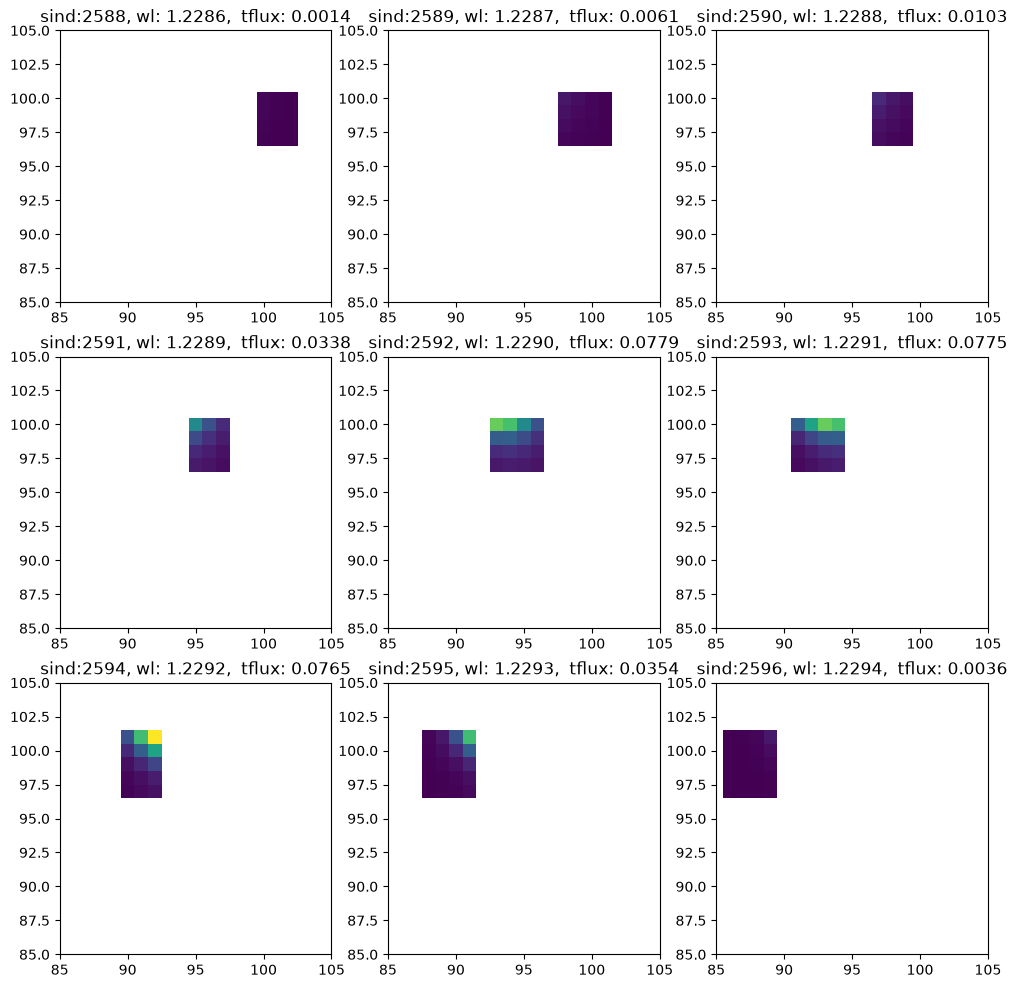

In [ ]:
fig, axs = plt.subplots(3,3, figsize=(12, 12))

for i, ax in enumerate(axs.ravel()):
    sind = uspec[54+i]
    msk = sind == specinds
    xin, yin = psfxs[msk], psfys[msk]

    mskarr = np.zeros(whicharr.shape[:2])*np.nan
    mskarr[xin, yin] = 1

    ax.imshow((psf_flux/np.sum(psf_flux)*mskarr).T, interpolation='nearest', origin='lower', vmin=0, vmax=0.02, aspect=1)
    ax.set_title(f'sind:{sind}, wl: {direct_model.spec_model.wave_microns[sind]:.4f},  tflux: {np.nansum(psf_flux/np.sum(psf_flux)*mskarr):.4f}')
    ax.set_xlim(85, 105)
    ax.set_ylim(85, 105)

Redo some of the above but with a *no-offset* PSF

In [ ]:
cancel_offset_params = trueish_paramst.copy()
cancel_offset_params[1] = -direct_model.x_slit0.to_value(u.arcsec)
cancel_offset_params[2] = -direct_model.y_slit0.to_value(u.arcsec)

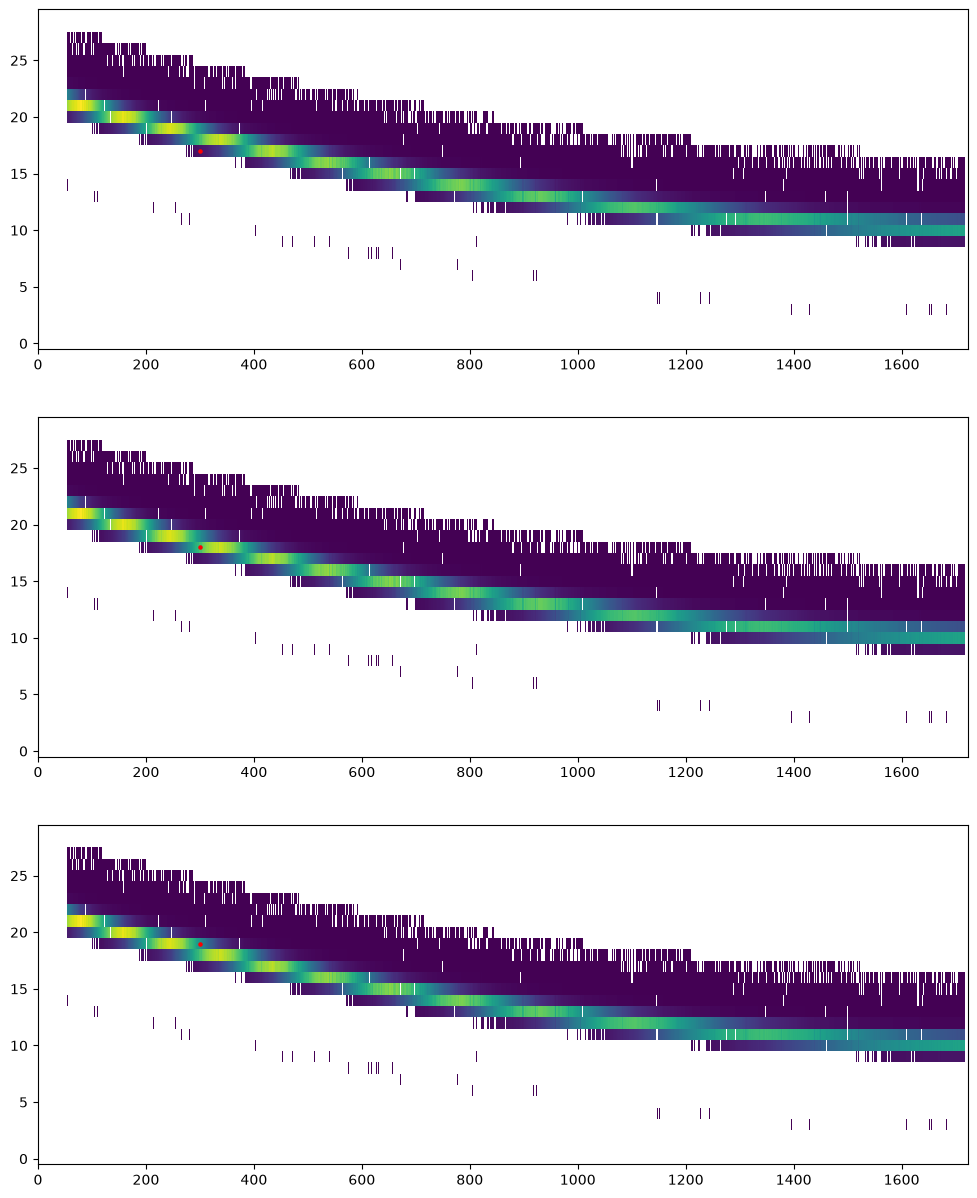

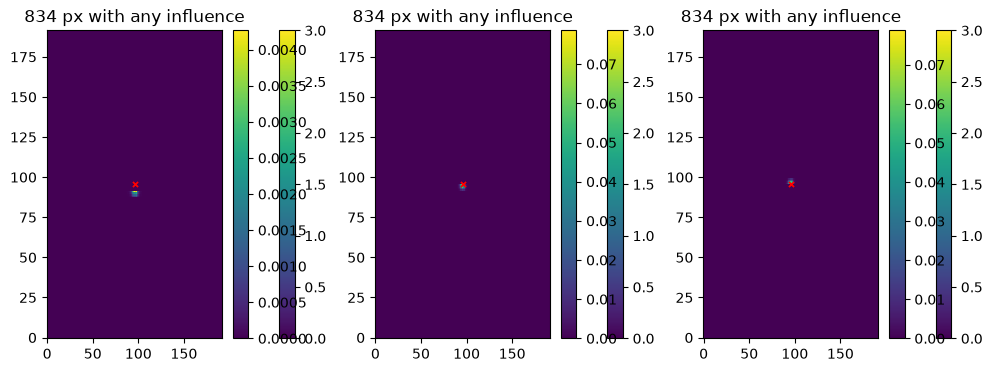

In [ ]:
fig1, axs1 = plt.subplots(3, 1, figsize=(12, 15))
fig2, axs2 = plt.subplots(1, 3, figsize=(12, 4))

stpx = 17

show_influences(300, stpx, axs1.ravel()[0], axs2.ravel()[0], False, params=cancel_offset_params)
show_influences(300, stpx+1, axs1.ravel()[1], axs2.ravel()[1], False, params=cancel_offset_params)
show_influences(300, stpx+2, axs1.ravel()[2], axs2.ravel()[2], False, params=cancel_offset_params);

show_influences(300, stpx, False, axs2.ravel()[0], False, params=cancel_offset_params, psfweight2=True)
show_influences(300, stpx+1, False, axs2.ravel()[1], False, params=cancel_offset_params, psfweight2=True)
show_influences(300, stpx+2, False, axs2.ravel()[2], False, params=cancel_offset_params, psfweight2=True);

What if the model itself has no offset?

In [ ]:
zoffset_params = trueish_paramst.copy()
zoffset_params[1] = zoffset_params[2] = 0

from copy import deepcopy

direct_model_copy = deepcopy(direct_model)
direct_model_copy._x_slit0_asec = direct_model_copy._y_slit0_asec = 0

/tmp/ipykernel_29483/2499676308.py:29: UserWarning: Adding colorbar to a different Figure <Figure size 1200x400 with 4 Axes> than <Figure size 1200x400 with 3 Axes> which fig.colorbar is called on.
  plt.colorbar(sc, ax=ax2)
/tmp/ipykernel_29483/2499676308.py:29: UserWarning: Adding colorbar to a different Figure <Figure size 1200x400 with 5 Axes> than <Figure size 1200x400 with 3 Axes> which fig.colorbar is called on.
  plt.colorbar(sc, ax=ax2)
/tmp/ipykernel_29483/2499676308.py:29: UserWarning: Adding colorbar to a different Figure <Figure size 1200x400 with 6 Axes> than <Figure size 1200x400 with 3 Axes> which fig.colorbar is called on.
  plt.colorbar(sc, ax=ax2)


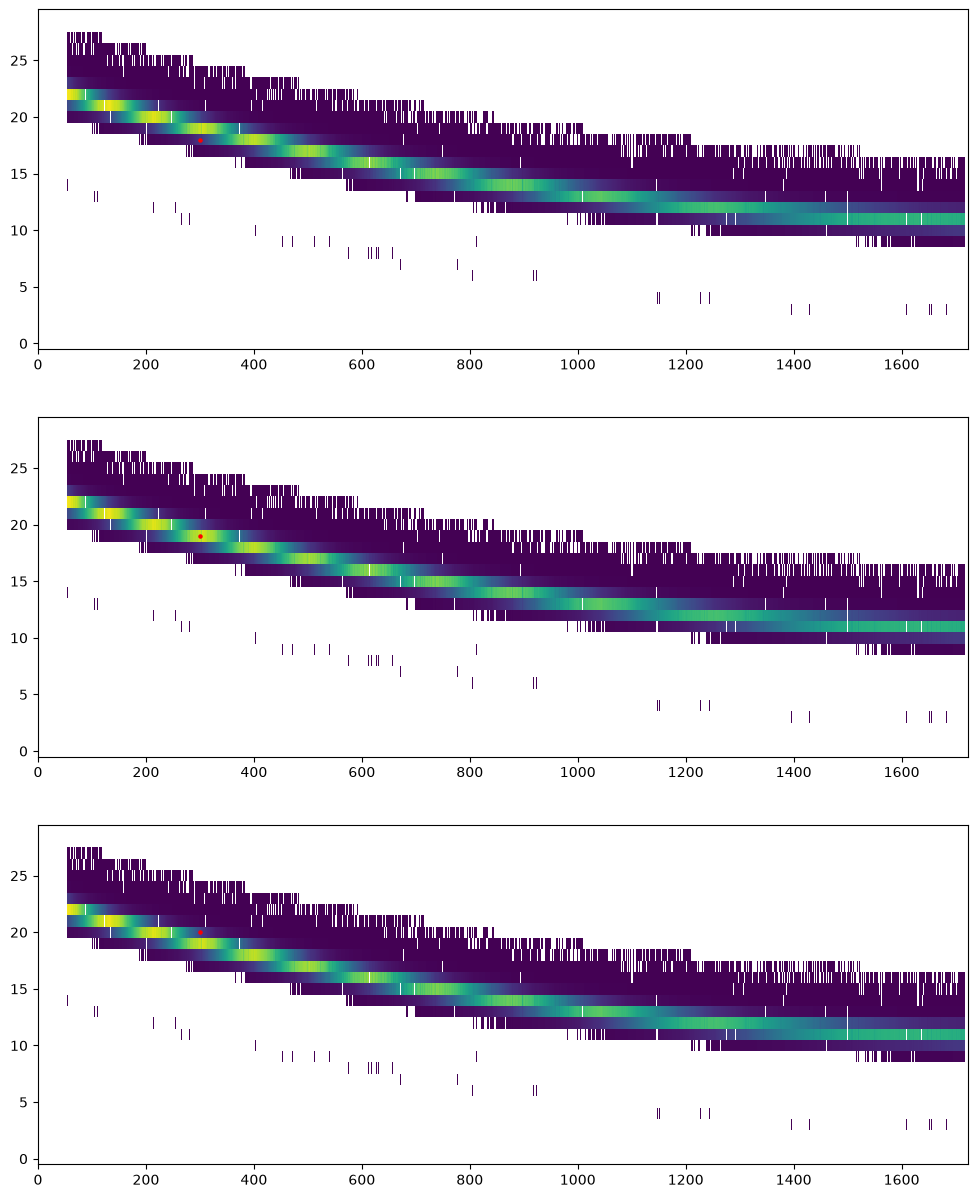

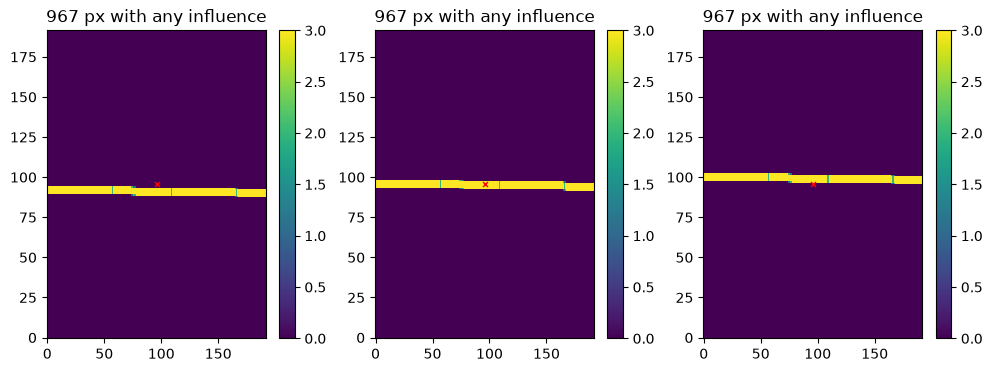

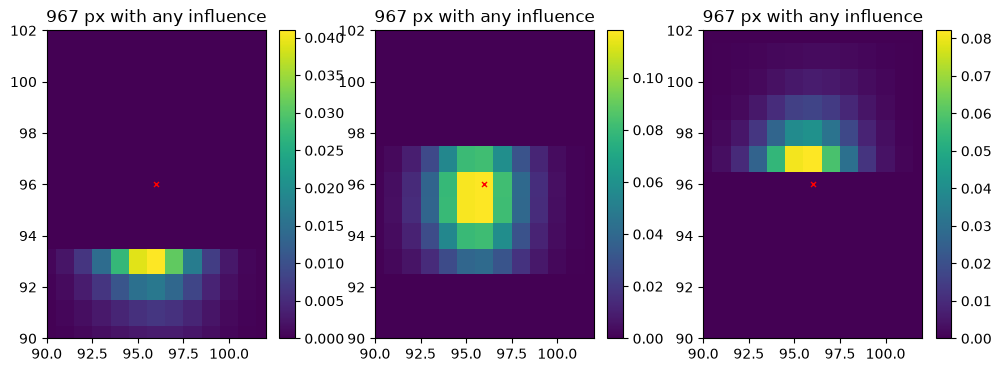

In [ ]:
fig1, axs1 = plt.subplots(3, 1, figsize=(12, 15))
fig2, axs2 = plt.subplots(1, 3, figsize=(12, 4))
fig22, axs22 = plt.subplots(1, 3, figsize=(12, 4)) # show the PSFs

stpx = 18
show_influences(300, stpx, axs1.ravel()[0], axs2.ravel()[0], False, params=zoffset_params, model=direct_model_copy)
show_influences(300, stpx+1, axs1.ravel()[1], axs2.ravel()[1], False, params=zoffset_params, model=direct_model_copy)
show_influences(300, stpx+2, axs1.ravel()[2], axs2.ravel()[2], False, params=zoffset_params, model=direct_model_copy);

show_influences(300, stpx, False, axs22.ravel()[0], False, params=zoffset_params, model=direct_model_copy, psfweight2=True)
show_influences(300, stpx+1, False, axs22.ravel()[1], False, params=zoffset_params, model=direct_model_copy, psfweight2=True)
show_influences(300, stpx+2, False, axs22.ravel()[2], False, params=zoffset_params, model=direct_model_copy, psfweight2=True);
for ax in axs22.ravel():
    ax.set_xlim(90, 102)
    ax.set_ylim(90, 102)


Aha! The banding is gone! Need to understand that better clearly.  What if we add an offset but leave the model's center 0?

/tmp/ipykernel_29483/2499676308.py:29: UserWarning: Adding colorbar to a different Figure <Figure size 1200x400 with 4 Axes> than <Figure size 1200x400 with 3 Axes> which fig.colorbar is called on.
  plt.colorbar(sc, ax=ax2)
/tmp/ipykernel_29483/2499676308.py:29: UserWarning: Adding colorbar to a different Figure <Figure size 1200x400 with 5 Axes> than <Figure size 1200x400 with 3 Axes> which fig.colorbar is called on.
  plt.colorbar(sc, ax=ax2)
/tmp/ipykernel_29483/2499676308.py:29: UserWarning: Adding colorbar to a different Figure <Figure size 1200x400 with 6 Axes> than <Figure size 1200x400 with 3 Axes> which fig.colorbar is called on.
  plt.colorbar(sc, ax=ax2)


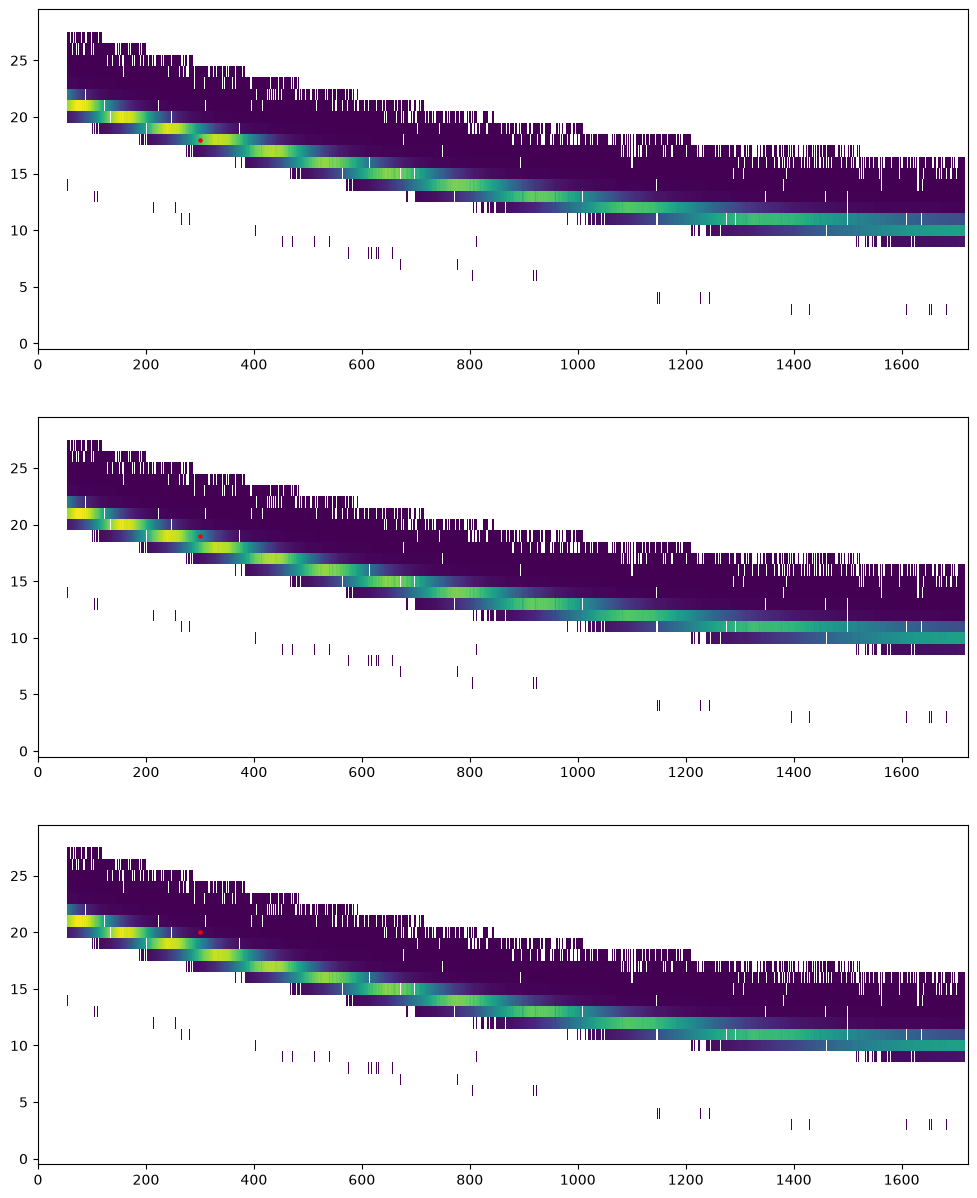

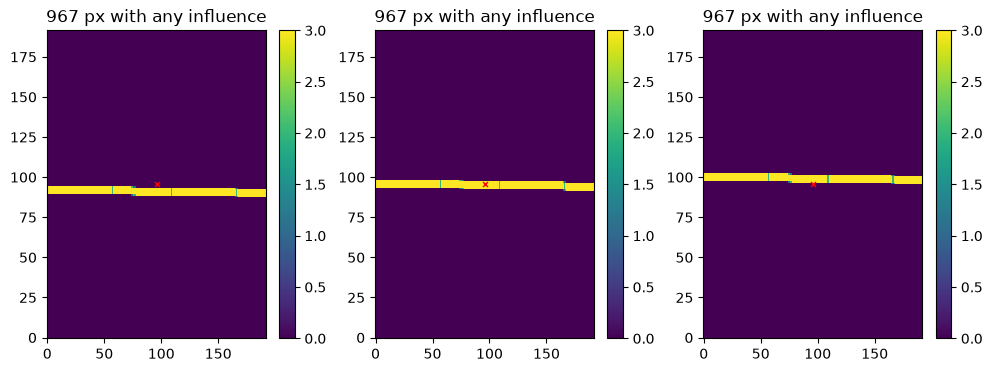

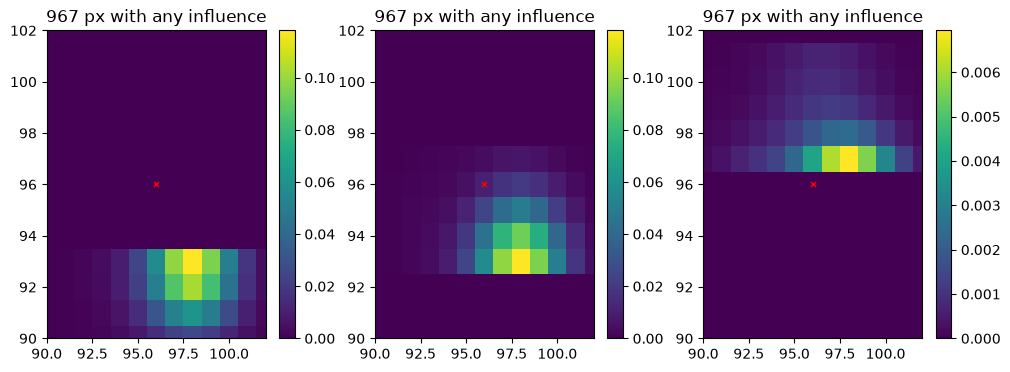

In [ ]:
fig1, axs1 = plt.subplots(3, 1, figsize=(12, 15))
fig2, axs2 = plt.subplots(1, 3, figsize=(12, 4))
fig22, axs22 = plt.subplots(1, 3, figsize=(12, 4)) # show the PSFs

stpx = 18
show_influences(300, stpx, axs1.ravel()[0], axs2.ravel()[0], False, params=cancel_offset_params, model=direct_model_copy)
show_influences(300, stpx+1, axs1.ravel()[1], axs2.ravel()[1], False, params=cancel_offset_params, model=direct_model_copy)
show_influences(300, stpx+2, axs1.ravel()[2], axs2.ravel()[2], False, params=cancel_offset_params, model=direct_model_copy);

show_influences(300, stpx, False, axs22.ravel()[0], False, params=cancel_offset_params, model=direct_model_copy, psfweight2=True)
show_influences(300, stpx+1, False, axs22.ravel()[1], False, params=cancel_offset_params, model=direct_model_copy, psfweight2=True)
show_influences(300, stpx+2, False, axs22.ravel()[2], False, params=cancel_offset_params, model=direct_model_copy, psfweight2=True);
for ax in axs22.ravel():
    ax.set_xlim(90, 102)
    ax.set_ylim(90, 102)


Still no banding.  So the asymmetry there is important... look at one of the previously banding points:

In [ ]:
whicharr, psf_flux = make_model_which(direct_model_copy, trueish_paramst, 1089, 13)
psfxs, psfys, specinds = np.where(whicharr)
uspec = np.sort(np.unique(specinds))
uspec

array([2535, 2536, 2537, 2538, 2539, 2540, 2541, 2542, 2543, 2544, 2545,
       2546, 2547, 2548, 2549, 2550, 2551, 2552, 2553, 2554, 2555, 2556,
       2557, 2558, 2559, 2560, 2561, 2562, 2563, 2564, 2565, 2566, 2567,
       2568, 2569, 2570, 2571, 2572, 2573, 2574, 2575, 2576, 2577, 2578,
       2579, 2580, 2581, 2582, 2583, 2584, 2585, 2586, 2587, 2588, 2589,
       2590, 2591, 2592, 2593, 2594, 2595, 2596, 2597, 2598, 2599, 2600,
       2601, 2602, 2603, 2604, 2605, 2606, 2607, 2608, 2609, 2610, 2611,
       2612, 2613, 2614, 2615, 2616, 2617, 2618, 2619, 2620, 2621, 2622,
       2623, 2624, 2625, 2626, 2627, 2628, 2629, 2630, 2631, 2632, 2633,
       2634, 2635, 2636, 2637, 2638, 2639, 2640, 2641, 2642, 2643, 2644,
       2645, 2646, 2647, 2648, 2649, 2650])

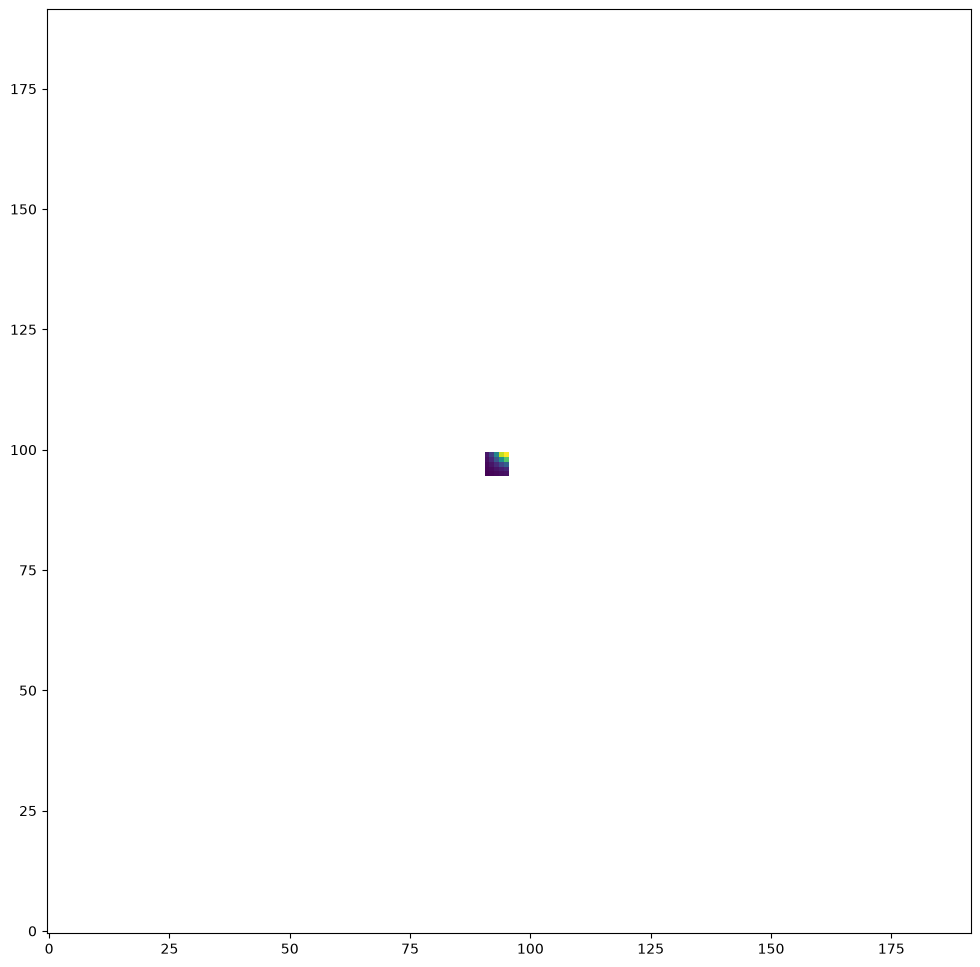

In [ ]:
sind = uspec[59]

msk = sind == specinds
xin, yin = psfxs[msk], psfys[msk]

mskarr = np.zeros(whicharr.shape[:2])*np.nan
mskarr[xin, yin] = 1

plt.figure(figsize=(12, 12))
plt.imshow((psf_flux/np.sum(psf_flux)*mskarr).T, interpolation='nearest', origin='lower', vmin=0, vmax=0.03);